# Домашнє завдання 4. Три прості діаграми й висновки
**Автор:** Лариса Дяченко · **Набір:** Coffee Quality & Pricing (Kaggle, Razan Ihab, CC0).

## Запитання й аудиторія
**Запитання:** від чого залежить ціна зеленої кави і як вона змінювалася за останні п'ять сезонів збору?

**Аудиторія:** закупівельник кав'ярні, який обирає постачальника і планує бюджет на закупівлю.

## 0. Дані
Завантаження й очищення – як у домашньому завданні 3: лишаю лише записи `Original`, щоб повторні партії не спотворювали результати.

In [51]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../lesson3/coffee_value_benchmark.csv")
meta = pd.read_csv("../lesson3/coffee_record_metadata.csv")
originals = meta[meta["record_type"] == "Original"]["record_id"]
df_clean = df[df["record_id"].isin(originals)].copy()
print(df_clean.shape)

(35000, 36)


## 1. Цифри: `describe()` і `groupby`

In [52]:
df_clean["price_usd_per_kg"].describe()

count    35000.000000
mean         4.811834
std          2.195118
min          1.780000
25%          3.460000
50%          4.190000
75%          5.360000
max         22.850000
Name: price_usd_per_kg, dtype: float64

In [53]:
#save as variable

price_by_trace = df_clean.groupby("traceability_level")["price_usd_per_kg"].median().sort_values()
print(price_by_trace)

traceability_level
Country        3.67
Region         4.01
Cooperative    4.86
Farm           5.09
Microlot       9.87
Name: price_usd_per_kg, dtype: float64


Мікролот коштує майже втричі дорожче ніж кава, про яку відомо лише країну

## 2. Діаграма 1: стовпчики (порівняння груп)

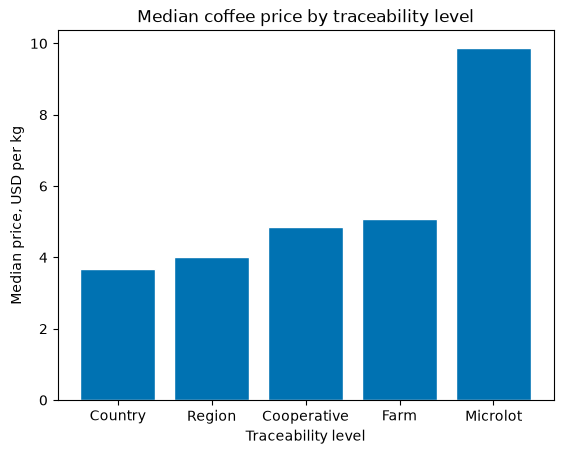

In [54]:
plt.bar(price_by_trace.index, price_by_trace.values, color="#0072B2", edgecolor="white")
plt.title("Median coffee price by traceability level")
plt.xlabel("Traceability level")
plt.ylabel("Median price, USD per kg")
plt.show()

In [55]:
print(round(price_by_trace["Microlot"] / price_by_trace["Country"], 1))
print(round(price_by_trace["Microlot"] / price_by_trace["Region"], 1))
print(round(price_by_trace["Microlot"] / price_by_trace["Cooperative"], 1))
print(round(price_by_trace["Microlot"] / price_by_trace["Farm"], 1))

2.7
2.5
2.0
1.9


Ціна кави мікролот перевищує ціну кави де відома лише країна або регіон у 2,5-2,7 рази, а кооперативу чи ферми приблизно вдвічі.

## 3. Діаграма 2: лінія (зміна в часі)

In [56]:
price_by_season = df_clean.groupby("harvest_season")["price_usd_per_kg"].median()
before = price_by_season["2020/21"]
after = price_by_season["2021/22"]
change_pct = (after - before) / before * 100
print(before, after, round(change_pct))

3.62 4.67 29


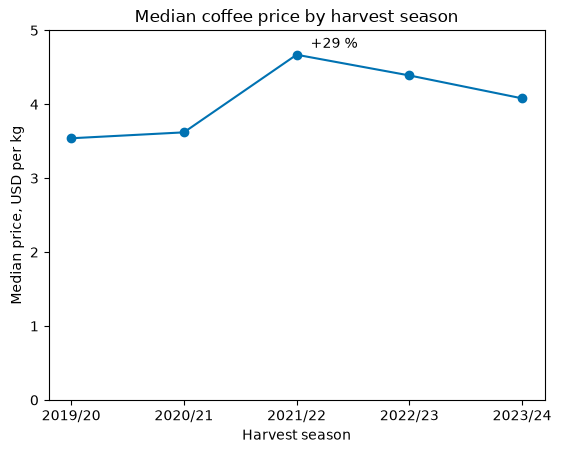

In [57]:
plt.plot(price_by_season.index, price_by_season.values, color="#0072B2", marker="o")
plt.title("Median coffee price by harvest season")
plt.xlabel("Harvest season")
plt.ylabel("Median price, USD per kg")
plt.ylim(0, 5)
plt.annotate(f"+{round(change_pct)} %", xy=("2021/22", after),
             xytext=(10, 5), textcoords="offset points")
plt.show()

Ціна майже не змінювалась у 2019/20–2020/21 (≈ 3.6 $/кг), потім за один сезон зросла на 29 % до 4.67 $/кг у 2021/22, а після цього знижувалась і в 2023/24 опустилася до 4.08 $/кг.

## 4. Діаграма 3: scatter (зв'язок двох чисел)

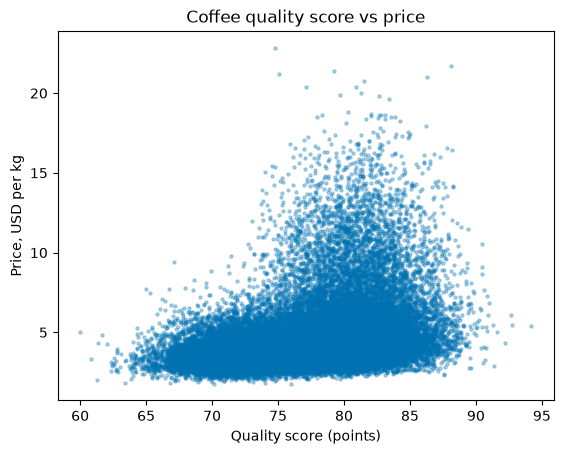

In [58]:
plt.scatter(df_clean["coffee_quality_score"], df_clean["price_usd_per_kg"],
            s=5, alpha=0.3, color="#0072B2")
plt.title("Coffee quality score vs price")
plt.xlabel("Quality score (points)")
plt.ylabel("Price, USD per kg")
plt.show()

Якість помірно пов'язана з ціною (r ≈ 0.34): при низькій якості всі партії дешеві, а серед партій з якістю 78–88 балів ціни розкидані від 2 до понад 20 $/кг; при цьому частина партій із найвищою оцінкою (90+) продається не дорожче за типову ціну. Отже, висока якість дає можливість дорожчого продажу, але не гарантує його.

## 5. Перевірка діаграми
Я поправила відображення діаграми «Median coffee price by harvest season»: додала `plt.ylim(0, 5)`. Коли почала описувати діаграму, звернула увагу, що різниця між цінами невелика, а графік виглядав дуже переконливо і створював враження, що ціна сильно змінювалася залежно від сезону.

Пізніше додала рядок `plt.annotate(...)`, щоб показати відсоток зміни ціни; цей рядок написав Claude на моє прохання.

Також перевірила: стовпчики на діаграмі 1 починаються від нуля; на всіх трьох діаграмах є назва й підписи осей; використано один колір.

## 6. AI
Claude допомагав підтягнути дані з попередньої домашньої роботи, а також склав план виконання домашнього завдання без коду, але з питаннями, які допомагали будувати хід виконання.